# SPX settlement forecasting
## 1. Goal, forecast definitions, and assumptions
Estimate 10th, 50th and 90th percentiles of **official settlement** returns, separately by horizon.
Weekly: prior week's final regular session close → following week's listed end-of-week **SPXW PM** settlement.
Monthly: current standard monthly settlement session close → next standard monthly **SET AM** settlement.
Reference prices are FRED SP500 closes. Labels are Cboe records, never substituted closes.

A forecast is eligible at **20:00 America/New_York** on its reference session. All inputs must be
available by **08:00 next regular session**, otherwise publication is suppressed. The forecast cell
checks once and safely retains previously issued rows. Unknown historical input publication is assumed
by the next-session 08:00 cutoff; unknown label publication becomes trainable the following regular session.
Live inputs use observed receipt times when publication times are unknown.

Verified Cboe dated calendar/contract imports are required to resolve historical holidays and eligibility.
Each horizon proceeds independently when its requirements are met. Missing evidence produces explicit
**pending** outputs; empty panels contain no synthetic market observations. Run all cells in order.


## 2. Configuration and environment checks
Edit this single cell for all run parameters. Full chronological backtesting is enabled by default.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from spx_forecast.config import Config
CONFIG = Config(
    start='2015-01-01', end='2026-11-06', reference_date='2026-11-06',
    raw=ROOT / 'data/raw', normalized=ROOT / 'data/normalized',
    imports=ROOT / 'data/imports', output=ROOT / 'artifacts',
    seed=42, refresh=False, run_expensive_backtest=True,
    timeout_seconds=15, retries=2,
)
CONFIG.prepare()


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from spx_forecast import workflow, plots
from spx_forecast.forecast import dependency_versions
from spx_forecast.backtest import metrics, model_key
from spx_forecast.features import FEATURES
plots.style()
pd.set_option('display.max_colwidth', 100)

def show_run_progress(event):
    if event['completed'] == 1 or event['completed'] == event['total'] or event['completed'] % 10 == 0:
        stage = 'training/development' if event['stage'] == 'development' else 'training/final test'
        print(f"{event['horizon'].title()} {stage}: {event['completed']}/{event['total']} expirations complete; "
              f"{event['models']} configurations per expiration; {event['training_count']} past outcomes in latest fit", flush=True)

def show_run_results(predictions, title):
    display(Markdown(f'### {title}'))
    if predictions.empty:
        display(Markdown('**No completed runs in this stage. Check the horizon status below.**'))
        return
    summary = metrics(predictions)
    summary = summary.loc[summary.regime.eq('all'),
                          ['horizon', 'model', 'count', 'interval_score_bps', 'coverage']].copy()
    summary['model'] = summary.model.map(plots.label)
    summary = summary.rename(columns={'horizon': 'Horizon', 'model': 'Model', 'count': 'Outcomes scored',
                                      'interval_score_bps': 'Interval score (bps)', 'coverage': '80% interval coverage'})
    display(summary.style.hide(axis='index').format({'Interval score (bps)': '{:.2f}', '80% interval coverage': '{:.1%}'}))

display(pd.Series(dependency_versions(), name='installed_version').to_frame())
display(Markdown('CPU models use one XGBoost thread. Missing model dependencies prevent model selection; source audits still run.'))


,installed_version
numpy,2.3.5
pandas,2.3.3
pyarrow,21.0.0
scikit-learn,1.7.2
xgboost,3.2.0
matplotlib,3.10.6
jupyterlab,4.4.7
nbformat,5.10.4
nbclient,0.10.2
nbconvert,7.16.6


CPU models use one XGBoost thread. Missing model dependencies prevent model selection; source audits still run.

## 3. Source downloads and data audit
Sources: [FRED SP500](https://fred.stlouisfed.org/series/SP500),
[Cboe volatility CSVs](https://www.cboe.com/tradable-products/vix/vix-historical-data),
[SPXW settlement records](https://www.cboe.com/index_settlement_values/weeklys_settlement_values/),
[SET records](https://www.cboe.com/index_settlement_values/),
[Cboe specifications](https://www.cboe.com/tradable-products/sp-500/spx-options/spx-specifications/),
[holidays](https://www.cboe.com/about/hours/us-options/), and dated Cboe expiration calendars.
Raw responses are content-addressed snapshots; normalized tables are Parquet. Source manifests retain
URLs, receipt timestamps, hashes and unknown publication timestamps. HTTP Last-Modified is not an
observation publication time. See `docs/imports.md` for verified official CSV imports.
FRED supplies roughly ten years of SP500 history. No alternative market-data provider is used.


In [3]:
state = workflow.prepare(CONFIG)
display(state['issues'])
display(state['audit'])
display(pd.DataFrame(state['plans']).T)

,dataset,status,reason
0,monthly_archive,pending,12 month-only SET values lack verified dates or usable values


,dataset,rows,start,end,missing_sessions,duplicate_records,valid_settlements,usable_forecasts
0,settlements_archive,1940,2015-01-02,2026-11-06,<NA>,0.0,1940,<NA>
1,settlements_monthly_archive,130,2016-01-15,2026-10-16,<NA>,0.0,130,<NA>
2,spx,2609,2016-11-07,2026-11-05,0,0.0,<NA>,<NA>
3,vix,3013,2015-01-02,2026-11-06,0,0.0,<NA>,<NA>
4,vix9d,2980,2015-01-02,2026-11-06,0,0.0,<NA>,<NA>
5,calendar,4018,2016-01-01,2026-12-31,<NA>,0.0,<NA>,<NA>
6,contracts,695,2016-01-15,2026-11-06,<NA>,0.0,<NA>,<NA>
7,settlements,2070,2015-01-02,2026-11-06,<NA>,0.0,2070,<NA>
8,weekly observations,344,NaT,NaT,NaN,NaN,NaN,344
9,monthly observations,118,NaT,NaT,NaN,NaN,NaN,118


,status,reason,training_start,development_start,test_start,test_end
weekly,ready,,2017-01-01 00:00:00,2022-01-01 00:00:00,2024-01-01 00:00:00,2025-12-31 00:00:00
monthly,ready,,2017-01-01 00:00:00,2022-01-01 00:00:00,2024-01-01 00:00:00,2025-12-31 00:00:00


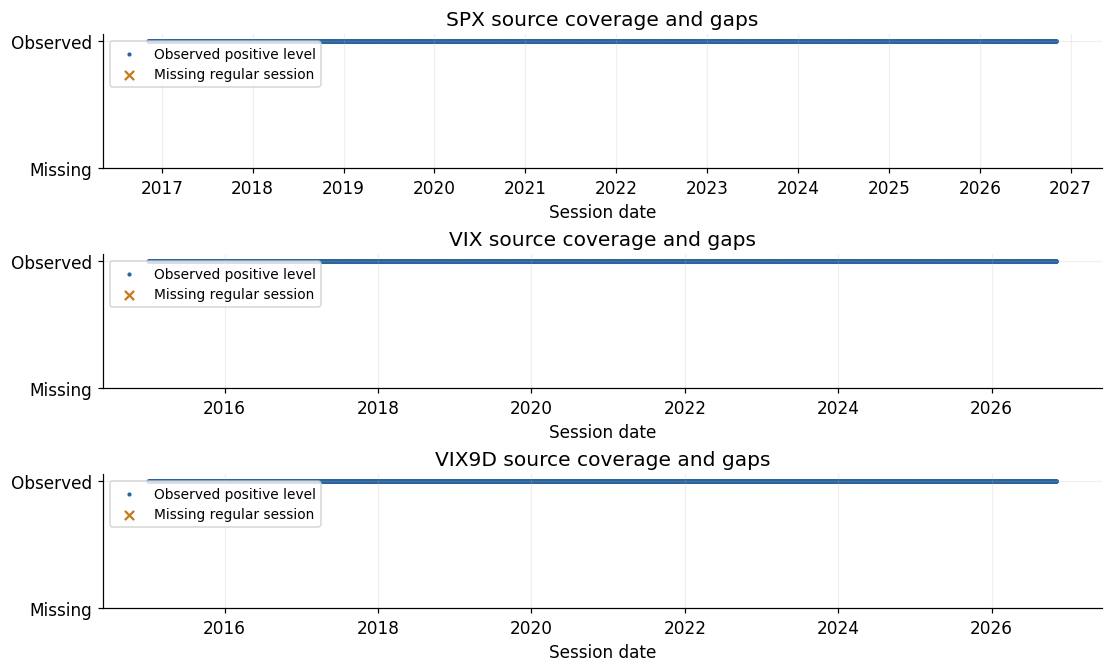

In [4]:
# Data coverage chart
figure = plots.coverage(state['datasets'], state['calendar'])
figure.savefig(CONFIG.output / 'data_coverage.png', bbox_inches='tight')
plt.show()

In [5]:
available_sources = [name for name in ('spx', 'vix', 'vix9d') if name in state['datasets']]
display(Markdown(f'Collected daily series: **{len(available_sources)}/3**. '
                 'Unknown missing-session counts require an official calendar; they are not zeros. '
                 'Pending requirements above must be resolved before interpreting model results.'))


Collected daily series: **3/3**. Unknown missing-session counts require an official calendar; they are not zeros. Pending requirements above must be resolved before interpreting model results.

## 4. Feature and label construction
One row per horizon/reference/expiration. The target is `10000 * log(official_settlement / reference_close)`
in log-return basis points. Features: 1/5/20-session log returns; sample realized volatility over 5/20
returns annualized by √252; VIX, VIX9D and VIX9D/VIX; close/20-session mean − 1; calendar days and
remaining regular sessions. Missing internal sessions invalidate complete windows; no forward fill.
Labels join on horizon, expiration **and settlement type**. Timing assumptions are retained on each row.


In [6]:
display(pd.DataFrame({'feature_order': FEATURES}))
for horizon, frame in state['observations'].items():
    display(Markdown(f'**{horizon.title()}: {len(frame)} usable feature rows**'))
    if len(frame):
        display(frame[['reference_date', 'expiration', 'reference_close', 'settlement', 'target',
                       'issue_time', 'label_available_at', 'timing_assumed']].tail(5))


,feature_order
0,return_1
1,return_5
2,return_20
3,realized_vol_5
4,realized_vol_20
5,vix
6,vix9d
7,vix9d_vix
8,price_mean20
9,calendar_days


**Weekly: 344 usable feature rows**

,reference_date,expiration,reference_close,settlement,target,issue_time,label_available_at,timing_assumed
339,2026-09-18,2026-09-25,7650.50,7743.41,120.711539,2026-09-21 12:00:00+00:00,2026-09-28 04:00:00+00:00,True
340,2026-09-25,2026-10-02,7743.41,7722.72,-26.755255,2026-09-28 12:00:00+00:00,2026-10-05 04:00:00+00:00,True
341,2026-10-02,2026-10-09,7722.72,7811.54,114.354939,2026-10-05 12:00:00+00:00,2026-10-12 04:00:00+00:00,True
342,2026-10-16,2026-10-23,7659.44,7623.68,-46.796813,2026-10-19 12:00:00+00:00,2026-10-26 04:00:00+00:00,True
343,2026-10-30,2026-11-06,7580.07,7376.86,-271.743606,2026-11-02 13:00:00+00:00,2026-11-09 05:00:00+00:00,True


**Monthly: 118 usable feature rows**

,reference_date,expiration,reference_close,settlement,target,issue_time,label_available_at,timing_assumed
113,2026-05-15,2026-06-18,7408.50,7508.43,133.983997,2026-05-18 12:00:00+00:00,2026-06-22 04:00:00+00:00,True
114,2026-06-18,2026-07-17,7500.58,7441.18,-79.509125,2026-06-22 12:00:00+00:00,2026-07-20 04:00:00+00:00,True
115,2026-07-17,2026-08-21,7457.69,7687.93,304.058517,2026-07-20 12:00:00+00:00,2026-08-24 04:00:00+00:00,True
116,2026-08-21,2026-09-18,7674.37,7657.35,-22.202345,2026-08-24 12:00:00+00:00,2026-09-21 04:00:00+00:00,True
117,2026-09-18,2026-10-16,7650.50,7757.09,138.362587,2026-09-21 12:00:00+00:00,2026-10-19 04:00:00+00:00,True


## 5. Benchmarks and model definitions
Separate horizon models use three XGBRegressors with `reg:quantileerror`, α = 0.10/0.50/0.90,
histogram trees, CPU, learning rate 0.03, full sampling, L1=0, seed 42. Weekly evaluates all eight
depth {1,2} × trees {100,200} × L2 {10,50} configurations, child weight 30. Monthly uses depth 1,
50 trees, L2=50, child weight 20. One development configuration is used for all three quantiles.

Comparison candidates: StandardScaler + linear QuantileRegressor (`highs`, L1 α ∈ {0.1,1,10}),
empirical historical return quantiles, and volatility-scaled historical quantiles. Scale is
`(VIX9D or VIX)/100 * sqrt(calendar_days/365)`. Historical basis-point returns are divided by
their own scales, quantiles estimated in the training window, then multiplied by the issue's scale.
All learned preprocessing is fit inside each expanding training window. Crossed quantiles are sorted
before scoring; raw crossing frequency is reported. Levels equal `reference_close * exp(return_bps/10000)`.


In [7]:
from spx_forecast.models import candidates
for horizon in ('weekly', 'monthly'):
    display(Markdown(f'**{horizon.title()} candidate configurations**'))
    display(pd.DataFrame(candidates(horizon)).fillna('—'))


**Weekly candidate configurations**

,family,alpha,max_depth,n_estimators,reg_lambda,min_child_weight
0,empirical,—,—,—,—,—
1,scaled,—,—,—,—,—
2,linear,0.1,—,—,—,—
3,linear,1.0,—,—,—,—
4,linear,10.0,—,—,—,—
5,xgb,—,1.0,100.0,10.0,30.0
6,xgb,—,1.0,100.0,50.0,30.0
7,xgb,—,1.0,200.0,10.0,30.0
8,xgb,—,1.0,200.0,50.0,30.0
9,xgb,—,2.0,100.0,10.0,30.0


**Monthly candidate configurations**

,family,alpha,max_depth,n_estimators,reg_lambda,min_child_weight
0,empirical,—,—,—,—,—
1,scaled,—,—,—,—,—
2,linear,0.1,—,—,—,—
3,linear,1.0,—,—,—,—
4,linear,10.0,—,—,—,—
5,xgb,—,1.0,50.0,50.0,20.0


## 6. Training and development runs
Require five complete initial training years after warm-up, at least two development years, and the
latest two complete calendar years before `end` as final testing. Evaluation periods are assigned by
expiration year. Complete official eligibility records (including ineligible weeks), features and labels
are required; gaps leave the horizon pending. Expanding fits use only labels available at each issue.
Final-test configurations are frozen and exported before the holdout cell runs.

80% interval score is `(upper−lower) + 10*(lower−actual)` for lower misses and
`+ 10*(actual−upper)` for upper misses, in log-return basis points.
Coverage and miss rates use the same forecast population. Wilson intervals are 95% and assume
independent outcomes; serial dependence/overlap can make them too narrow. Volatility regimes use the
initial training window's fixed median VIX9D (weekly) or VIX (monthly).

The run plan below separates the required complete training years from development and final testing.
Each forecast refits its models on all prior available labels; earlier usable warm-up outcomes can also
be included. Progress messages report completed expirations and the number of past outcomes in each fit.
These are expanding fits, so there is no single epoch-based training run.


In [8]:
display(Markdown('### Training, development and test split'))
display(workflow.split_summary(state))
print('START: training + development evaluation', flush=True)
workflow.development(CONFIG, state, progress=show_run_progress)
development_predictions = workflow.predictions(state, 'development')
development_metrics = metrics(development_predictions)
show_run_results(development_predictions, 'Completed training/development runs')
display(pd.Series(state['statuses'], name='horizon_status').to_frame())
display(pd.DataFrame(state['frozen']).T)

### Training, development and test split

,Horizon,Stage,Period,Outcomes,Configurations
0,Weekly,Required initial training,2017-2021,173,Refit for each forecast
1,Weekly,Training + development evaluation,2022-2023,71,13
2,Weekly,Training + final test evaluation,2024-2025,69,2 frozen finalists
3,Monthly,Required initial training,2017-2021,60,Refit for each forecast
4,Monthly,Training + development evaluation,2022-2023,24,6
5,Monthly,Training + final test evaluation,2024-2025,24,2 frozen finalists


START: training + development evaluation
Weekly training/development: 1/71 expirations complete; 13 configurations per expiration; 174 past outcomes in latest fit
Weekly training/development: 10/71 expirations complete; 13 configurations per expiration; 183 past outcomes in latest fit
Weekly training/development: 20/71 expirations complete; 13 configurations per expiration; 193 past outcomes in latest fit
Weekly training/development: 30/71 expirations complete; 13 configurations per expiration; 203 past outcomes in latest fit
Weekly training/development: 40/71 expirations complete; 13 configurations per expiration; 213 past outcomes in latest fit
Weekly training/development: 50/71 expirations complete; 13 configurations per expiration; 223 past outcomes in latest fit
Weekly training/development: 60/71 expirations complete; 13 configurations per expiration; 233 past outcomes in latest fit
Weekly training/development: 70/71 expirations complete; 13 configurations per expiration; 243 past

### Completed training/development runs

Horizon,Model,Outcomes scored,Interval score (bps),80% interval coverage
monthly,Linear α=0.1,24,2158.37,58.3%
monthly,Linear α=1,24,2124.39,50.0%
monthly,Linear α=10,24,2124.39,50.0%
monthly,Historical quantiles,24,2161.62,50.0%
monthly,Volatility-scaled quantiles,24,1890.01,66.7%
monthly,"XGB depth=1, trees=50, L2=50",24,1955.94,62.5%
weekly,Linear α=0.1,71,926.09,67.6%
weekly,Linear α=1,71,949.62,70.4%
weekly,Linear α=10,71,949.62,70.4%
weekly,Historical quantiles,71,952.76,70.4%


,horizon_status
weekly,Completed training/development: 923 predictions; finalist configurations frozen
monthly,Completed training/development: 144 predictions; finalist configurations frozen


,benchmark,ml,volatility_threshold,plan
weekly,{'family': 'scaled'},"{'family': 'xgb', 'max_depth': 2, 'min_child_weight': 30, 'n_estimators': 100, 'reg_lambda': 50}",13.67,"{'status': 'ready', 'reason': '', 'training_start': 2017-01-01 00:00:00, 'development_start': 20..."
monthly,{'family': 'scaled'},"{'family': 'xgb', 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 50, 'reg_lambda': 50}",15.88,"{'status': 'ready', 'reason': '', 'training_start': 2017-01-01 00:00:00, 'development_start': 20..."


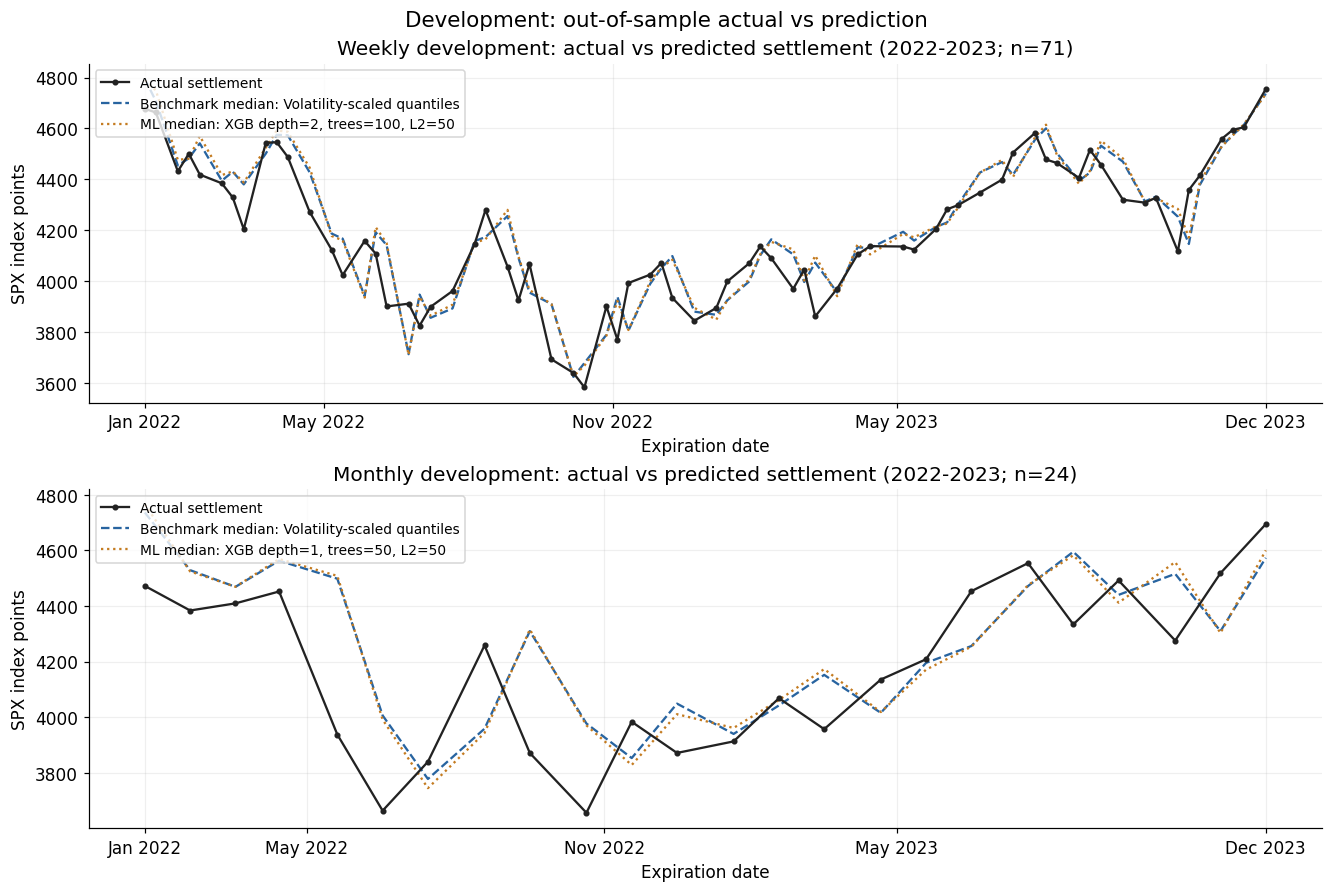

In [9]:
# Development actual vs predicted settlement chart
figure = plots.actual_vs_prediction(development_predictions, state['frozen'], 'development')
figure.savefig(CONFIG.output / 'development_actual_vs_prediction.png', bbox_inches='tight')
plt.show()

## 7. Final test runs
Only the development-selected benchmark and ML candidate enter the final test. Refits remain expanding:
earlier holdout labels may train later issues only after publication. This is sequential evaluation,
not a single fixed model fit. Holdout results never tune hyperparameters.


In [10]:
print('START: training + final test evaluation using frozen configurations', flush=True)
workflow.final_test(CONFIG, state, progress=show_run_progress)
final_predictions = workflow.predictions(state, 'final')
final_metrics = metrics(final_predictions)
show_run_results(final_predictions, 'Completed final test runs')

START: training + final test evaluation using frozen configurations
Weekly training/final test: 1/69 expirations complete; 2 configurations per expiration; 245 past outcomes in latest fit
Weekly training/final test: 10/69 expirations complete; 2 configurations per expiration; 254 past outcomes in latest fit
Weekly training/final test: 20/69 expirations complete; 2 configurations per expiration; 264 past outcomes in latest fit
Weekly training/final test: 30/69 expirations complete; 2 configurations per expiration; 274 past outcomes in latest fit
Weekly training/final test: 40/69 expirations complete; 2 configurations per expiration; 284 past outcomes in latest fit
Weekly training/final test: 50/69 expirations complete; 2 configurations per expiration; 294 past outcomes in latest fit
Weekly training/final test: 60/69 expirations complete; 2 configurations per expiration; 304 past outcomes in latest fit
Weekly training/final test: 69/69 expirations complete; 2 configurations per expiratio

### Completed final test runs

Horizon,Model,Outcomes scored,Interval score (bps),80% interval coverage
monthly,Volatility-scaled quantiles,24,1331.57,79.2%
monthly,"XGB depth=1, trees=50, L2=50",24,1403.37,87.5%
weekly,Volatility-scaled quantiles,69,662.48,78.3%
weekly,"XGB depth=2, trees=100, L2=50",69,672.99,78.3%


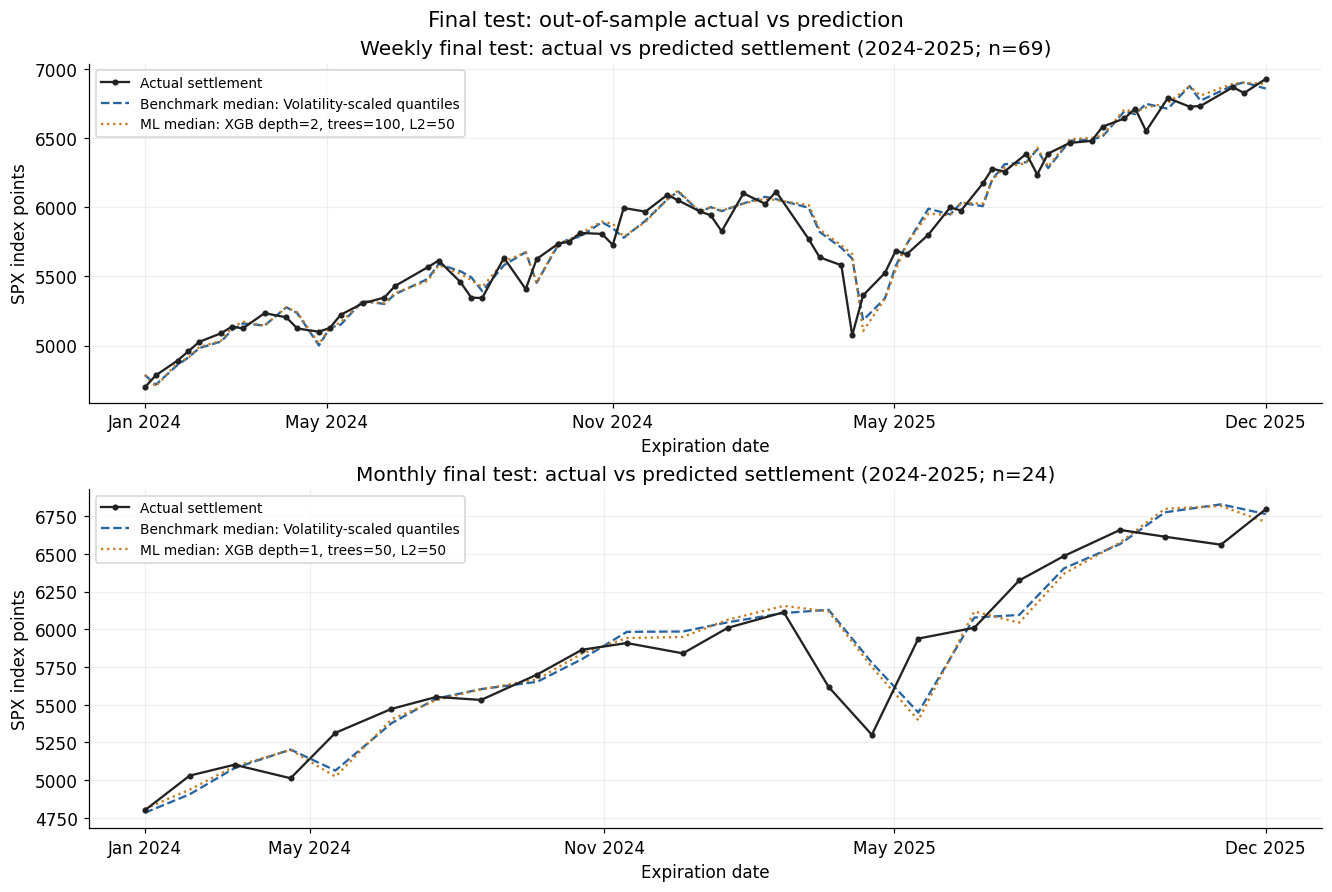

In [11]:
# Final-test actual vs predicted settlement chart
figure = plots.actual_vs_prediction(final_predictions, state['frozen'], 'final_test')
figure.savefig(CONFIG.output / 'final_test_actual_vs_prediction.png', bbox_inches='tight')
plt.show()

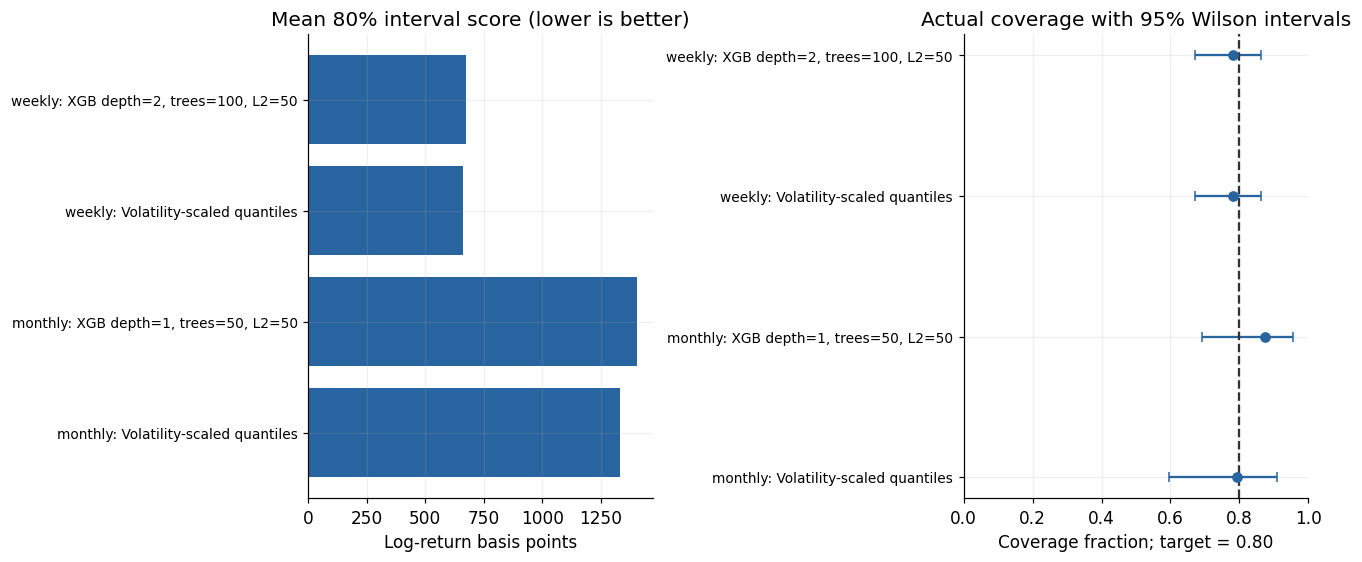

In [12]:
# Final model comparison chart
figure = plots.comparisons(final_metrics)
figure.savefig(CONFIG.output / 'final_model_comparisons.png', bbox_inches='tight')
plt.show()

### Actual vs predicted by year: 2024, 2025 and 2026
Weekly and monthly charts with one panel per year. 2024-2025 are the final-test predictions above.
2026 lies after the frozen test window, so it is a **post-holdout extension**: the same frozen finalists
are refit before each forecast using only labels available at that issue time. It never tunes anything.


In [13]:
YEAR_PANELS, EXTENSION_YEAR = (2024, 2025, 2026), 2026
extension_predictions = workflow.post_holdout_predictions(CONFIG, state, EXTENSION_YEAR)
yearly_predictions = pd.concat([final_predictions, extension_predictions], ignore_index=True)


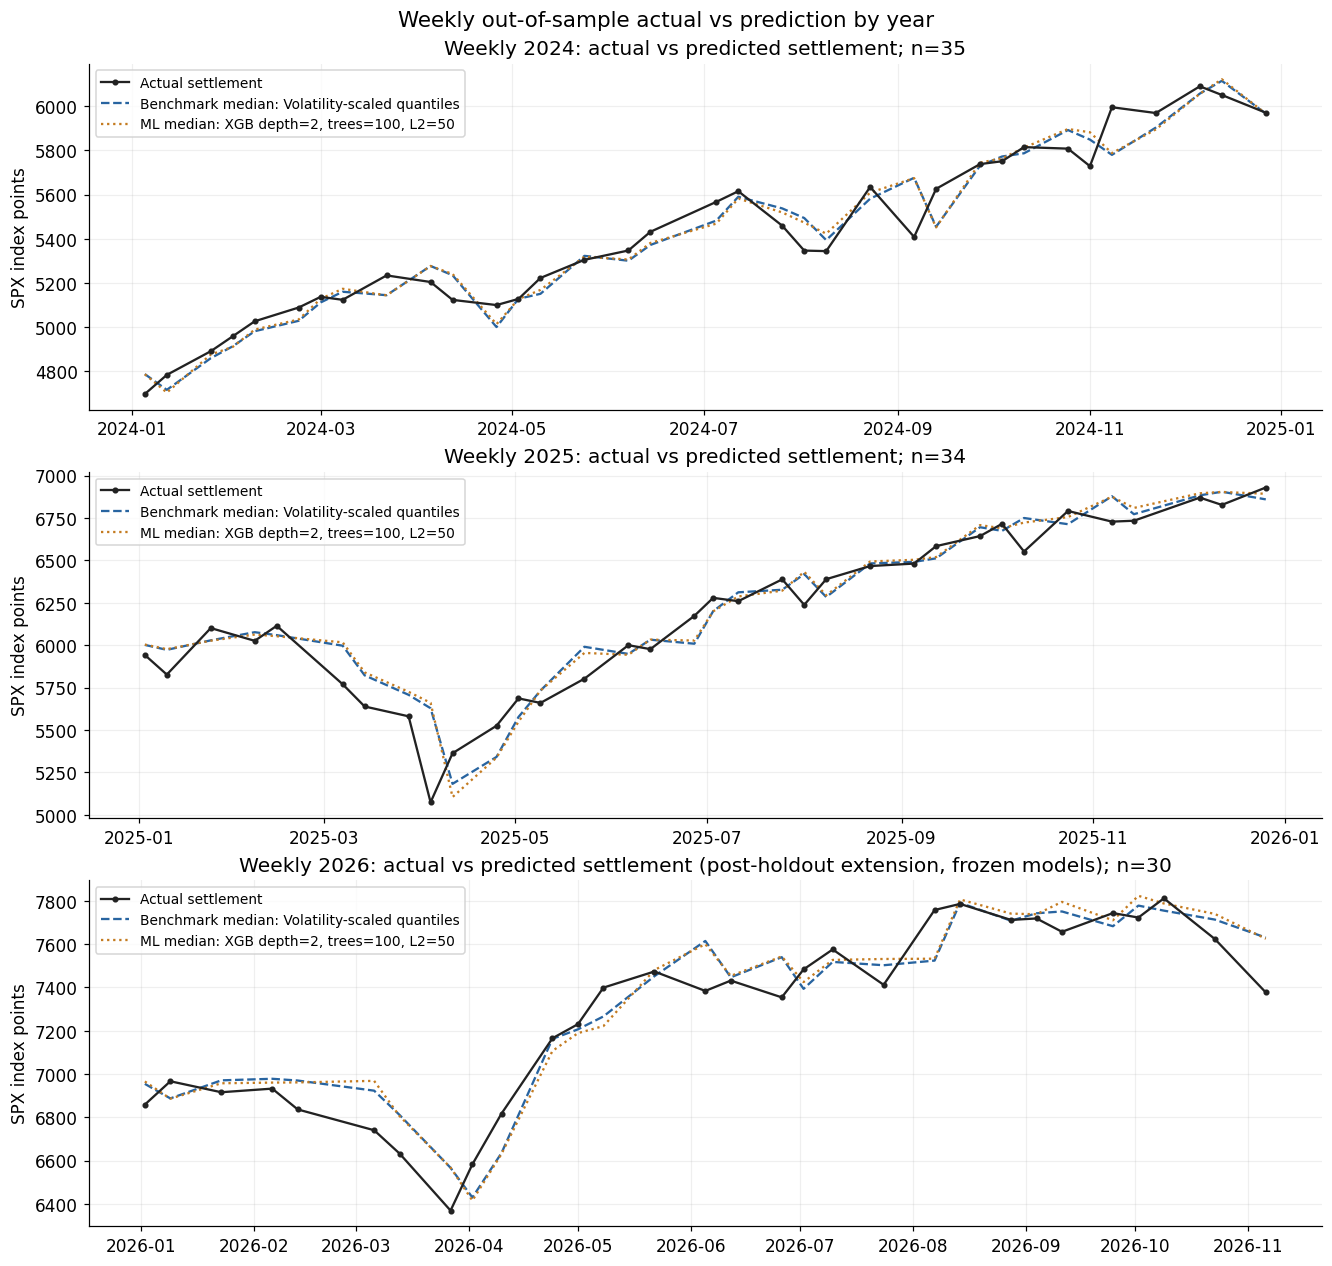

In [14]:
# Weekly actual vs predicted settlement, 2024-2026
figure = plots.yearly_actual_vs_prediction(yearly_predictions, state['frozen'], 'weekly',
                                           YEAR_PANELS, (EXTENSION_YEAR,))
figure.savefig(CONFIG.output / 'weekly_actual_vs_prediction_by_year.png', bbox_inches='tight', dpi=130)
plt.show()

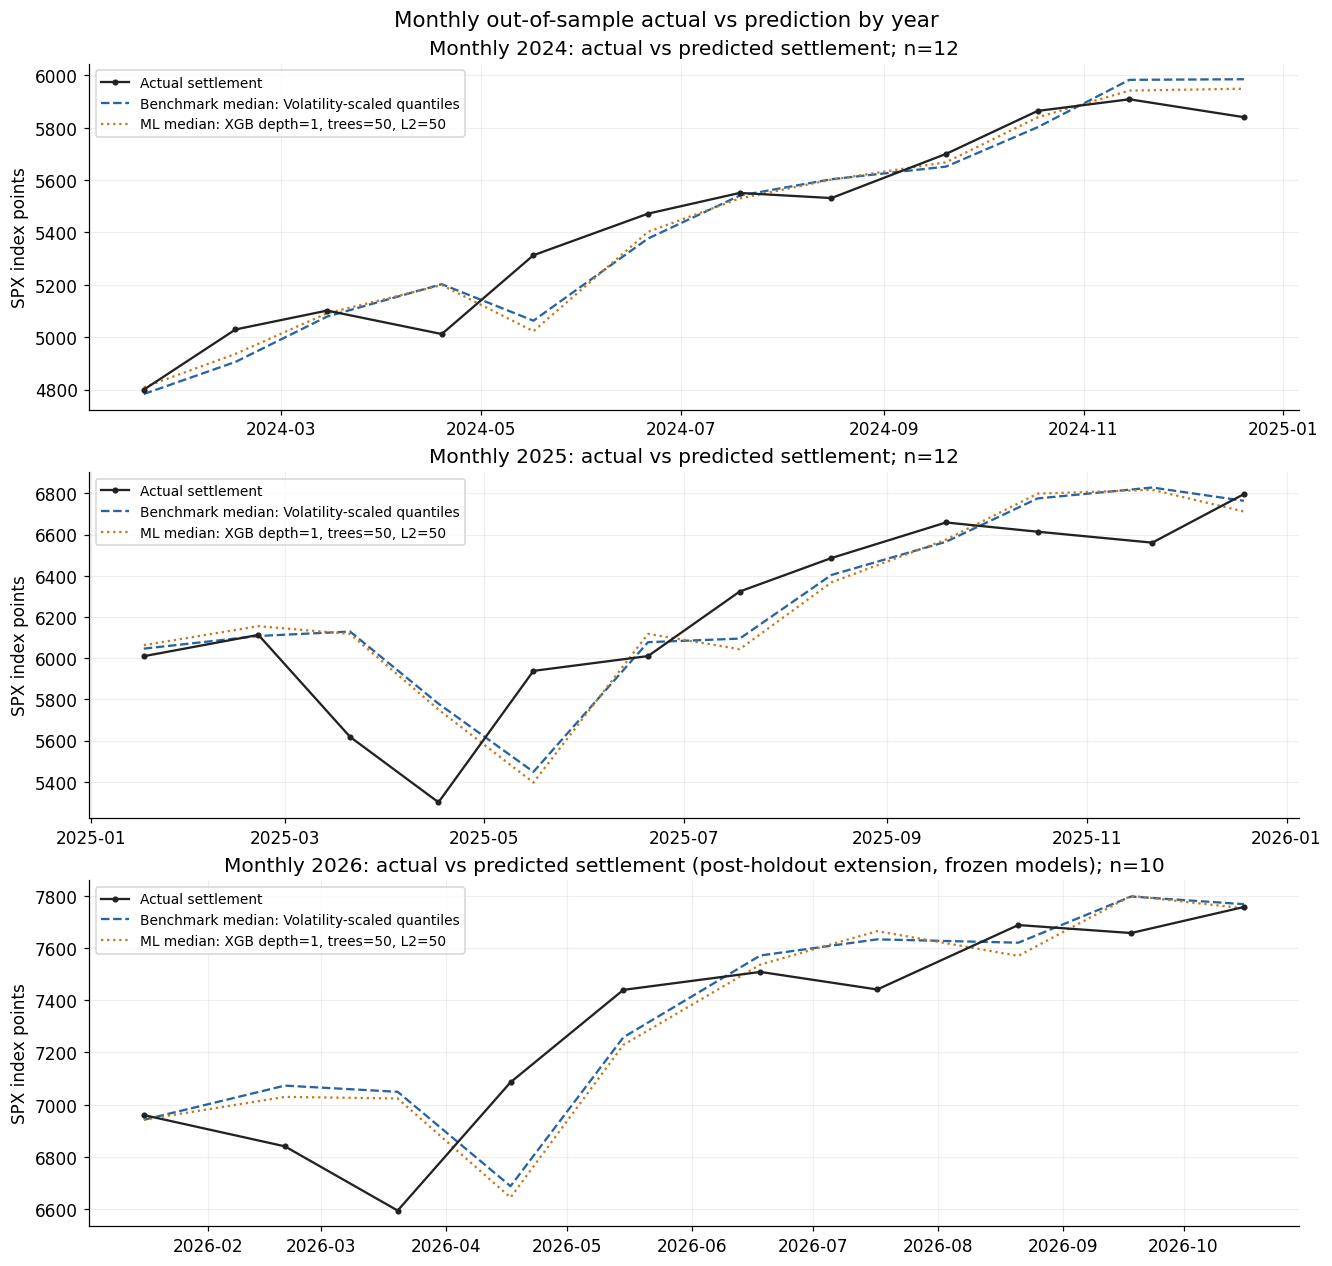

In [15]:
# Monthly actual vs predicted settlement, 2024-2026
figure = plots.yearly_actual_vs_prediction(yearly_predictions, state['frozen'], 'monthly',
                                           YEAR_PANELS, (EXTENSION_YEAR,))
figure.savefig(CONFIG.output / 'monthly_actual_vs_prediction_by_year.png', bbox_inches='tight', dpi=130)
plt.show()

### Forecast ranges table: 2025 and 2026
The selected model's 10th percentile, median and 90th percentile settlement levels for every scored weekly and monthly expiration, next to the official settlement. `within_80` marks settlements inside the 10th–90th range. 2026 rows are the post-holdout extension. Saved to `artifacts/forecast_ranges_2025_2026.csv`.

In [ ]:
# Selected-model 10th / median / 90th percentile settlement levels, 2025 and 2026
selected_range_table = workflow.forecast_range_table(yearly_predictions, state['selected'], (2025, 2026))
selected_range_table.to_csv(CONFIG.output / 'forecast_ranges_2025_2026.csv', index=False)
display(selected_range_table)

,horizon,reference_date,expiration,reference_close,p10_level,median_level,p90_level,actual_level,within_80
0,weekly,2024-12-27,2025-01-03,5970.84,5860.51,6002.04,6092.81,5942.47,True
1,weekly,2025-01-03,2025-01-10,5942.47,5831.80,5972.85,6064.98,5827.04,False
2,weekly,2025-01-17,2025-01-24,5996.66,5877.42,6028.88,6126.61,6101.24,True
3,weekly,2025-01-31,2025-02-07,6040.53,5906.20,6076.97,6187.45,6025.99,True
4,weekly,2025-02-07,2025-02-14,6025.99,5902.07,6059.61,6161.42,6114.63,True
5,weekly,2025-02-28,2025-03-07,5954.50,5797.66,5997.31,6127.16,5770.20,False
6,weekly,2025-03-07,2025-03-14,5770.20,5577.12,5822.49,5981.66,5638.94,True
7,weekly,2025-03-21,2025-03-28,5667.56,5519.03,5707.61,5829.01,5580.94,True
8,weekly,2025-03-28,2025-04-04,5580.94,5403.01,5628.63,5775.56,5074.08,False
9,weekly,2025-04-04,2025-04-11,5074.08,4672.63,5182.84,5531.45,5363.36,True


## 8. Model selection and forecast generation
Promote ML only if its paired final-test interval score is lower **and** its coverage is at least as
close to 80% as the frozen benchmark's coverage. Otherwise retain the benchmark. This final-test
promotion rule makes the selected model's reported holdout performance descriptive, not a new unbiased
estimate. The issue timestamp below is actual execution time, not a backdated scheduled timestamp.
Set `reference_date` to an official weekly or monthly reference session; both need not coincide.
Rerun this cell for one new availability check. It never waits, duplicates, or changes an issued row.


In [16]:
forecast_rows, forecast_status = workflow.forecast_once(CONFIG, state)
display(forecast_status)
display(forecast_rows)
display(pd.DataFrame(state['selected']).T)


,horizon,checked_at,timing_status,status
0,weekly,2026-11-09 00:46:37.228088+00:00,pending: verified contract/calendar or reference inputs unavailable,pending: no eligible contract with complete features for configured reference_date
1,monthly,2026-11-09 00:46:37.228088+00:00,pending: verified contract/calendar or reference inputs unavailable,pending: no eligible contract with complete features for configured reference_date


,horizon,reference_date,actual_issue_time,expiration,settlement_type,reference_close,lower,median,upper,model_version,timing_status


,family
weekly,scaled
monthly,scaled


## 9. Results, limitations, and artifact exports

In [17]:
backtest_predictions, all_metrics = workflow.export(CONFIG, state)
display(all_metrics)

,horizon,stage,model,regime,interval_score_bps,coverage,lower_miss_rate,upper_miss_rate,median_width_points,median_absolute_error_points,median_absolute_error_bps,count,coverage_wilson_lower,coverage_wilson_upper,crossing_frequency
0,monthly,development,"{""alpha"":0.1,""family"":""linear""}",above,2356.350543,0.600000,0.250000,0.150000,383.535182,171.564601,423.709843,20,0.386582,0.781193,0.0
1,monthly,development,"{""alpha"":0.1,""family"":""linear""}",below_or_equal,1168.456862,0.500000,0.500000,0.000000,378.130961,176.934145,395.913395,4,0.150039,0.849961,0.0
2,monthly,development,"{""alpha"":1,""family"":""linear""}",above,2299.981093,0.500000,0.250000,0.250000,344.494815,171.420663,427.781990,20,0.299298,0.700702,0.0
3,monthly,development,"{""alpha"":1,""family"":""linear""}",below_or_equal,1246.454969,0.500000,0.500000,0.000000,408.643586,176.934145,395.913395,4,0.150039,0.849961,0.0
4,monthly,development,"{""alpha"":10,""family"":""linear""}",above,2299.981093,0.500000,0.250000,0.250000,344.494815,171.420663,427.781990,20,0.299298,0.700702,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,weekly,development,"{""family"":""xgb"",""max_depth"":2,""min_child_weight"":30,""n_estimators"":100,""reg_lambda"":50}",all,855.146984,0.690141,0.169014,0.140845,238.917689,63.986823,156.820652,71,0.575160,0.785603,0.0
65,weekly,development,"{""family"":""xgb"",""max_depth"":2,""min_child_weight"":30,""n_estimators"":200,""reg_lambda"":10}",all,912.929389,0.676056,0.197183,0.126761,233.830731,70.009942,168.364087,71,0.560612,0.773428,0.0
66,weekly,development,"{""family"":""xgb"",""max_depth"":2,""min_child_weight"":30,""n_estimators"":200,""reg_lambda"":50}",all,901.698745,0.690141,0.183099,0.126761,228.010777,62.526171,161.828412,71,0.575160,0.785603,0.0
67,weekly,final_test,"{""family"":""scaled""}",all,662.475090,0.782609,0.101449,0.115942,245.293428,69.951874,113.213703,69,0.671817,0.863592,0.0


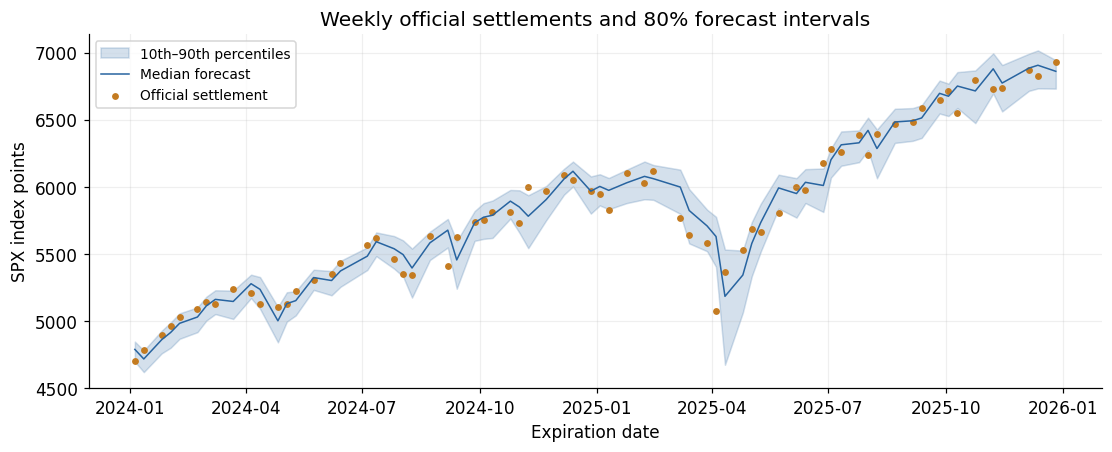

In [18]:
# Weekly 80% settlement interval chart
selected_key = model_key(state['selected']['weekly']) if 'weekly' in state['selected'] else None
figure = plots.outcomes(final_predictions, 'weekly', selected_key)
figure.savefig(CONFIG.output / 'weekly_settlement_intervals.png', bbox_inches='tight')
plt.show()

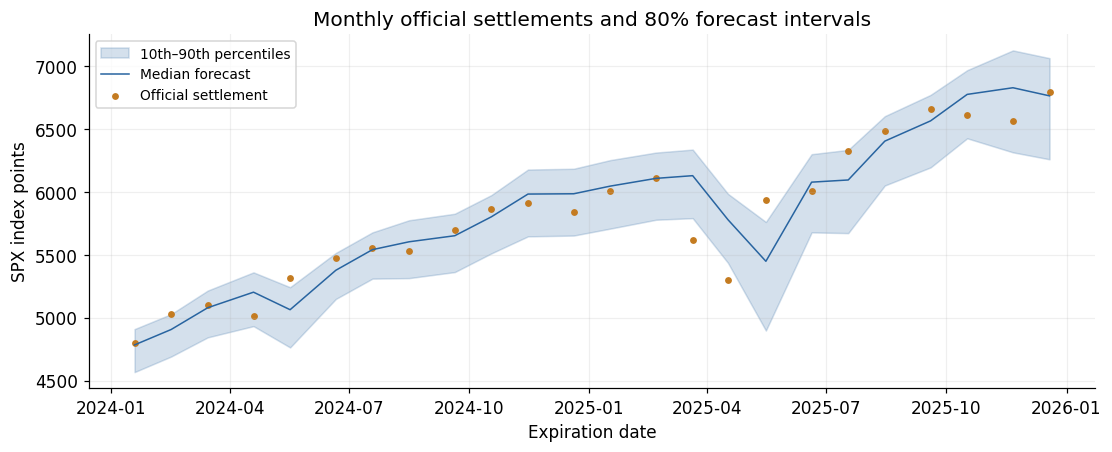

In [19]:
# Monthly 80% settlement interval chart
selected_key = model_key(state['selected']['monthly']) if 'monthly' in state['selected'] else None
figure = plots.outcomes(final_predictions, 'monthly', selected_key)
figure.savefig(CONFIG.output / 'monthly_settlement_intervals.png', bbox_inches='tight')
plt.show()

In [20]:
# Interval width chart
figure.savefig(CONFIG.output / 'interval_widths.png', bbox_inches='tight')
plt.show()

In [21]:
if final_metrics.empty:
    display(Markdown('**No verified final-test model results or settlement ranges are available in this run.** '
                     'Pending panels show unavailable evidence, not observed performance.'))
else:
    for horizon, selected in state['selected'].items():
        result = final_metrics.loc[final_metrics.horizon.eq(horizon) & final_metrics.regime.eq('all') &
                                   final_metrics.model.eq(model_key(selected))].iloc[0]
        display(Markdown(f"**{horizon.title()}**: {int(result['count'])} forecasts; "
                         f"coverage {result.coverage:.1%}; mean interval score {result.interval_score_bps:.2f} bps."))
display(pd.Series(state['statuses'], name='remaining_requirements').to_frame())
display(pd.DataFrame({'artifact': sorted(p.name for p in CONFIG.output.iterdir() if p.is_file())}))


**Weekly**: 69 forecasts; coverage 78.3%; mean interval score 662.48 bps.

**Monthly**: 24 forecasts; coverage 79.2%; mean interval score 1331.57 bps.

,remaining_requirements
weekly,"evaluated; selected {""family"":""scaled""}"
monthly,"evaluated; selected {""family"":""scaled""}"


,artifact
0,backtest_predictions.csv
1,backtest_validation.json
2,calendar_validation.json
3,connectivity.json
4,contract_coverage.csv
5,contract_validation.json
6,data_audit.csv
7,data_coverage.png
8,development_actual_vs_prediction.png
9,early_calendar_archive_check.json


Historical unknown publication timing is an explicit assumption, not measured latency. FRED delivery
can miss the required 08:00 cutoff; verified late inputs suppress publication. Downloaded history may be
revised and is not a point-in-time vintage archive. Official calendar/specification changes must be
represented in the verified imports. Only verified dated SET values enter training; unresolved early
records remain separate from the scored population.
Intervals describe conditional settlement ranges, with no guarantee of future 80% coverage.

Exports: forecast CSV/availability status, backtest predictions, metrics, source manifest and audit,
frozen configurations, run metadata and figures in `artifacts/`; normalized Parquet in `data/normalized/`;
raw snapshots in `data/raw/`; fitted model and metadata artifacts only when supported models can be fit.
See `README.md` and `docs/imports.md` for setup, execution and pending requirements.
